# 01. Data check

Goal: load the exported data and confirm it matches the book (94 patients, 12,625 genes; NEG 42, BCR/ABL 37, ALL1/AF4 10, E2A/PBX1 5). No modelling here.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

X = pd.read_csv('../data/expression.csv', index_col='patient', dtype={'patient': str})
labels = pd.read_csv('../data/labels.csv', index_col='patient', dtype={'patient': str})
y = labels['class']

## Shape, labels and class counts

In [2]:
expected = {'NEG': 42, 'BCR/ABL': 37, 'ALL1/AF4': 10, 'E2A/PBX1': 5}

print('expression (patients x genes):', X.shape)
print('rows match labels in the same order:', X.index.equals(labels.index))
print('unique patient ids:', X.index.is_unique, '| unique gene ids:', X.columns.is_unique)

counts = y.value_counts()
check = pd.DataFrame({'book': pd.Series(expected), 'data': counts})
check['match'] = check['book'] == check['data']
check

expression (patients x genes): (94, 12625)
rows match labels in the same order: True
unique patient ids: True | unique gene ids: True


,book,data,match
NEG,42,42,True
BCR/ABL,37,37,True
ALL1/AF4,10,10,True
E2A/PBX1,5,5,True


## Values: range, summary and missing data

In [3]:
v = X.to_numpy().ravel()
q1, med, q3 = np.percentile(v, [25, 50, 75])
summary = pd.DataFrame({'book': [1.99, 5.47, 5.62, 14.04],
                        'data': [v.min(), med, v.mean(), v.max()]},
                       index=['min', 'median', 'mean', 'max']).round(2)
print(summary)
print(f'quartiles: {q1:.2f}, {med:.2f}, {q3:.2f}')
print(f'share of values between 4 and 7: {((v >= 4) & (v <= 7)).mean():.1%}')
print('missing values:', int(X.isna().sum().sum()))
print('column dtypes:', X.dtypes.unique())
print('genes with zero variance:', int((X.std() == 0).sum()))
print('control probes (AFFX):', int(X.columns.str.startswith('AFFX').sum()))

         book   data
min      1.99   1.98
median   5.47   5.47
mean     5.62   5.62
max     14.04  14.04
quartiles: 4.12, 5.47, 6.83
share of values between 4 and 7: 54.9%


missing values: 0
column dtypes: [dtype('float64')]


genes with zero variance: 0
control probes (AFFX): 67


## Class balance and value distribution per class

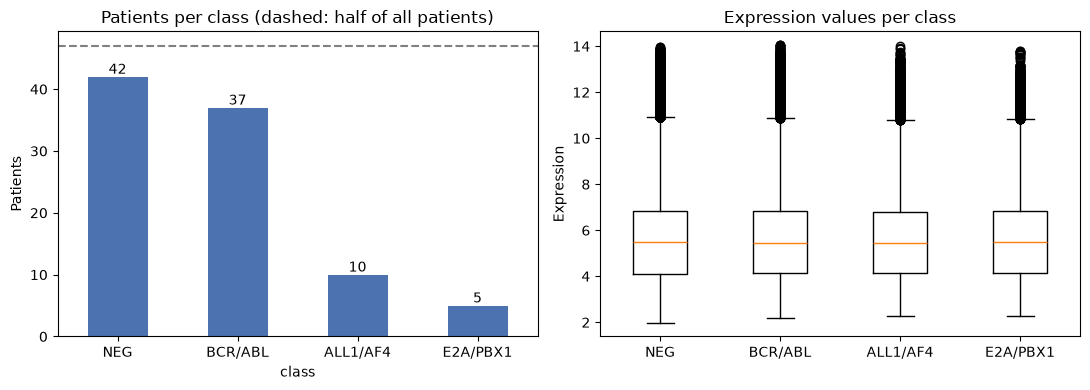

majority-class rate (always NEG): 44.7%
class  ALL1/AF4  BCR/ABL  E2A/PBX1  NEG
BT                                     
B             0        2         1    2
B1           10        1         0    8
B2            0       19         0   16
B3            0        8         1   14
B4            0        7         3    2


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))

counts.plot.bar(ax=ax[0], color='#4c72b0', rot=0)
for i, n in enumerate(counts):
    ax[0].text(i, n + 0.5, str(n), ha='center')
ax[0].axhline(len(y) * 0.5, ls='--', color='grey')
ax[0].set_title('Patients per class (dashed: half of all patients)')
ax[0].set_ylabel('Patients')

ax[1].boxplot([X[y == c].to_numpy().ravel() for c in counts.index], tick_labels=counts.index)
ax[1].set_title('Expression values per class')
ax[1].set_ylabel('Expression')

plt.tight_layout()
plt.savefig('../results/data_check.png', dpi=120)
plt.show()

print(f'majority-class rate (always NEG): {counts.max() / len(y):.1%}')
print(pd.crosstab(labels['BT'], y))

## Notes

**Matched the book**

- 94 patients and 12,625 genes; labels line up with the expression rows.
- Class counts: NEG 42, BCR/ABL 37, ALL1/AF4 10, E2A/PBX1 5.
- Value range and summary: min 1.98 (book 1.99), median 5.47, mean 5.62, max 14.04. The minimum differs in the second decimal only; the book rounds, and the data version is the current `ALL` package (1.52.0).
- No missing values, no constant genes, all columns numeric.
- The per-class value distributions are almost identical, as the book states. The class signal is therefore in individual genes, not in overall expression level.

**Differences and points to handle**

- The book says most values lie between 4 and 7. Here 55% do; the interquartile range is 4.12 to 6.83, so the statement is true as a description of the central half of the values, not of nearly all of them.
- The data contains 67 control probes (names starting with AFFX). The book's filter log reports 19 removed at that step, after other steps had already removed some. The two numbers are not directly comparable and the book's log is not reproduced here.
- The book's subsetting code writes `ALL$mol.bio`; the column is `mol.biol`. R partial matching makes it work, and the export script uses the full name.
- All 10 ALL1/AF4 patients have `BT` = B1, and the other `BT` stages contain none. B-cell stage and class are therefore not independent for this class. This is not in the book. It is worth remembering when interpreting results.
- Always predicting NEG gives 44.7%, the reference point any model must beat. E2A/PBX1 has five patients, so any resampling scheme leaves very few of them in a test set.

**Open for the next step:** baseline scope, scaling, gene selection, models, evaluation scheme and extension are not decided.